
# Main-text figures (Fig. 1-7)

This notebook regenerates every data-driven figure of the main text from the metric
tables in `data/metrics/`. It is split into two independent stages:

| Stage | Reads | Writes | When to run |
|-------|-------|--------|-------------|
| **1 - Extract** | `data/metrics/**.xlsx` | `results/figure_data/figN_*.csv` | once (the CSVs are committed to git) |
| **2 - Plot**    | `results/figure_data/figN_*.csv` | `results/figures/main/figN_*.{png,pdf}` | whenever you restyle a figure |

Because each plot is drawn from a small committed CSV, **changing a figure never
requires re-reading the Excel tables or recomputing anything** - just re-run Stage 2.

Figure -> article map: `fig1` reference benchmark (Fig. 1, Table 1), `fig2` layer-wise
quality (Fig. 2), `fig3` k-mer sweep (Fig. 3), `fig4` unseen-virus P@5 (Fig. 4, Table 2),
`fig5` CROSS P@5 (Fig. 5, Table 3), `fig6` P@k vs k (Fig. 6), `fig7` P@10 vs CROSS P@10
per layer (Fig. 7).

In [1]:
# Make figure_io importable whether Jupyter is launched from the repo root or
# from the visualization/ folder, then apply the shared plotting style.
import sys, pathlib
_here = pathlib.Path.cwd()
if not (_here / "figure_io.py").exists() and (_here / "visualization" / "figure_io.py").exists():
    _here = _here / "visualization"
sys.path.insert(0, str(_here))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import figure_io as fio
from figure_io import MODELS, DISPLAY, MODEL_COLOR, save_table, load_table, save_figure

fio.set_style()
print("repository root :", fio.ROOT)
print("reading metrics :", fio.DATA_METRICS.relative_to(fio.ROOT).as_posix())
print("writing results :", fio.RESULTS.relative_to(fio.ROOT).as_posix())

repository root : C:\Users\aleks\Documents\glm_vectorizing
reading metrics : data/metrics
writing results : results


## Stage 1 - Extract the numbers behind each figure

Each cell reads the raw metric tables, aggregates them and writes one committed CSV.
Run this stage once; the CSVs it produces are tracked in git.

### Fig. 1 - reference benchmark: best layer of each model (ARI, P@5, silhouette)

In [2]:
rows = []
for metric in ["ARI", "P5", "silh"]:
    for model in MODELS:
        mat = pd.read_excel(fio.DATA_METRICS / model / f"{metric}.xlsx").to_numpy(dtype=float)
        layer_means = np.nanmean(mat, axis=1)
        best = int(np.nanargmax(layer_means))            # best layer = highest mean over sub-samples
        rows.append({"metric": metric, "model": model, "best_layer": best,
                     "mean": float(np.nanmean(mat[best])), "std": float(np.nanstd(mat[best]))})
save_table(pd.DataFrame(rows), "fig1_reference_benchmark")

  numbers  ->  results/figure_data/fig1_reference_benchmark.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig1_reference_benchmark.csv')

### Fig. 2 - layer-wise ARI and Precision@5 for every model

In [3]:
rows = []
for metric in ["ARI", "P5"]:
    for model in MODELS:
        mat = pd.read_excel(fio.DATA_METRICS / model / f"{metric}.xlsx").to_numpy(dtype=float)
        mean, std = np.nanmean(mat, axis=1), np.nanstd(mat, axis=1)
        for layer in range(len(mean)):
            rows.append({"metric": metric, "model": model, "layer": layer,
                         "mean": float(mean[layer]), "std": float(std[layer])})
save_table(pd.DataFrame(rows), "fig2_layerwise")

  numbers  ->  results/figure_data/fig2_layerwise.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig2_layerwise.csv')

### Fig. 3 - k-mer spectrum sweep (ARI, P@5, silhouette vs word length k)

The sweep recomputes k-mer vectors from the reference FASTA samples (~30 min, needs
`data/random_samples/`). Those samples are **not** shipped with the repo, so the summary
table produced by `visualization/kmer_sweep.py` is committed instead. This cell simply
copies that summary into the standard `figure_data/` location if it is present locally;
otherwise the already-committed `fig3_kmer_sweep.csv` is used unchanged.

In [4]:
kmer_xlsx = fio.DATA_METRICS / "kmer_sweep" / "kmer_sweep_results.xlsx"
if kmer_xlsx.exists():
    save_table(pd.read_excel(kmer_xlsx, sheet_name="summary"), "fig3_kmer_sweep")
else:
    print("kmer_sweep_results.xlsx not found -> keeping the committed fig3_kmer_sweep.csv")
    print("(regenerate the source with visualization/kmer_sweep.py if you have data/random_samples/).")

  numbers  ->  results/figure_data/fig3_kmer_sweep.csv


### Fig. 4 - generalisation to unseen viruses: Precision@5 (forward + reverse complement)

In [5]:
df5 = pd.read_excel(fio.DATA_METRICS / "P@K_new_virus" / "P@5.xlsx")
df5 = df5[df5["model"].isin(MODELS)]
groups = [("Egovirales_preproc", "forward", "Egovirales"),
          ("Mriyavirales_preproc", "forward", "Mriyavirales"),
          ("REVERSECOMPLEMENTEgovirales_preproc", "RC", "Egovirales (RC)"),
          ("REVERSECOMPLEMENTMriyavirales_preproc", "RC", "Mriyavirales (RC)")]
rows = []
for virus, typ, label in groups:
    for model in MODELS:
        sub = df5[(df5["virus"] == virus) & (df5["type"] == typ) & (df5["model"] == model)]
        rows.append({"group": label, "model": model,
                     "mean": float(sub["mean_P@K"].iloc[0]), "std": float(sub["std_P@K"].iloc[0])})
save_table(pd.DataFrame(rows), "fig4_newvirus_p5")

  numbers  ->  results/figure_data/fig4_newvirus_p5.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig4_newvirus_p5.csv')

### Fig. 5 - forward <-> reverse-complement proximity: CROSS Precision@5

In [6]:
df5 = pd.read_excel(fio.DATA_METRICS / "P@K_new_virus" / "P@5.xlsx")
df5 = df5[df5["model"].isin(MODELS)]
rows = []
for virus, label in [("Egovirales_preproc", "Egovirales"), ("Mriyavirales_preproc", "Mriyavirales")]:
    for model in MODELS:
        sub = df5[(df5["virus"] == virus) & (df5["type"] == "cross") & (df5["model"] == model)]
        rows.append({"group": label, "model": model,
                     "mean": float(sub["mean_P@K"].iloc[0]), "std": float(sub["std_P@K"].iloc[0])})
save_table(pd.DataFrame(rows), "fig5_cross_p5")

  numbers  ->  results/figure_data/fig5_cross_p5.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig5_cross_p5.csv')

### Fig. 6 - Precision@k as a function of the neighbourhood size k

In [7]:
rows = []
for k in range(1, 11):
    dfk = pd.read_excel(fio.DATA_METRICS / "P@K_new_virus" / f"P@{k}.xlsx")
    for virus, label in [("Egovirales_preproc", "Egovirales"), ("Mriyavirales_preproc", "Mriyavirales")]:
        for model in MODELS:
            sub = dfk[(dfk["virus"] == virus) & (dfk["type"] == "forward") & (dfk["model"] == model)]
            rows.append({"virus": label, "model": model, "k": k, "mean": float(sub["mean_P@K"].iloc[0])})
save_table(pd.DataFrame(rows), "fig6_pk_vs_k")

  numbers  ->  results/figure_data/fig6_pk_vs_k.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig6_pk_vs_k.csv')

### Fig. 7 - per-layer trade-off: own-order density vs cross-order proximity

Built from the pairwise Egovirales <-> Mriyavirales comparison in
`data/metrics/<model>/pairwise_Egovirales_vs_Mriyavirales/`:

* **y - Precision@10 within the own order.** `pk_fwd_1_in_2` scores Egovirales fragments
  and `pk_fwd_2_in_1` scores Mriyavirales fragments, each in a space that also contains
  the other order; we average the two directions.
* **x - CROSS Precision@10 between the orders.** `cross_1->2_fwd_fwd` counts how often an
  Egovirales fragment retrieves a Mriyavirales neighbour instead of its own kind.

An ideal representation sits **top-left**: a dense own-order cluster that is well separated
from the other order. Every point is one layer; the 4-mer baseline has no layers and is
drawn as a single star.


In [8]:
PAIRWISE = "pairwise_Egovirales_vs_Mriyavirales"

def pairwise_layer_mean(model, filename):
    """Mean over the 50 reference samples -> one value per layer."""
    path = fio.DATA_METRICS / model / PAIRWISE / filename
    return pd.read_excel(path).set_index("layer").mean(axis=1)

rows = []
for model in MODELS:
    pk_1_in_2 = pairwise_layer_mean(model, "pk_fwd_1_in_2_matrix.xlsx")   # Egovirales
    pk_2_in_1 = pairwise_layer_mean(model, "pk_fwd_2_in_1_matrix.xlsx")   # Mriyavirales
    cross = pairwise_layer_mean(model, "cross_1→2_fwd_fwd_matrix.xlsx")

    density = (pk_1_in_2 + pk_2_in_1) / 2        # y: own-order density, both directions
    for layer in density.index:                  # layer is "-" for the layer-less 4-mer
        rows.append({"model": model, "layer": layer,
                     "p_at_10": float(density[layer]),
                     "cross_p_at_10": float(cross[layer])})
save_table(pd.DataFrame(rows), "fig7_pk_vs_cross")


  numbers  ->  results/figure_data/fig7_pk_vs_cross.csv


WindowsPath('C:/Users/aleks/Documents/glm_vectorizing/results/figure_data/fig7_pk_vs_cross.csv')

## Stage 2 - Render the figures from the committed numbers

Every cell below reads only a CSV from `results/figure_data/` - it never touches
`data/metrics/`. Restyle freely and re-run; nothing is recomputed.

### Fig. 1

  figure   ->  results/figures/main/fig1_reference_benchmark.{png,pdf}


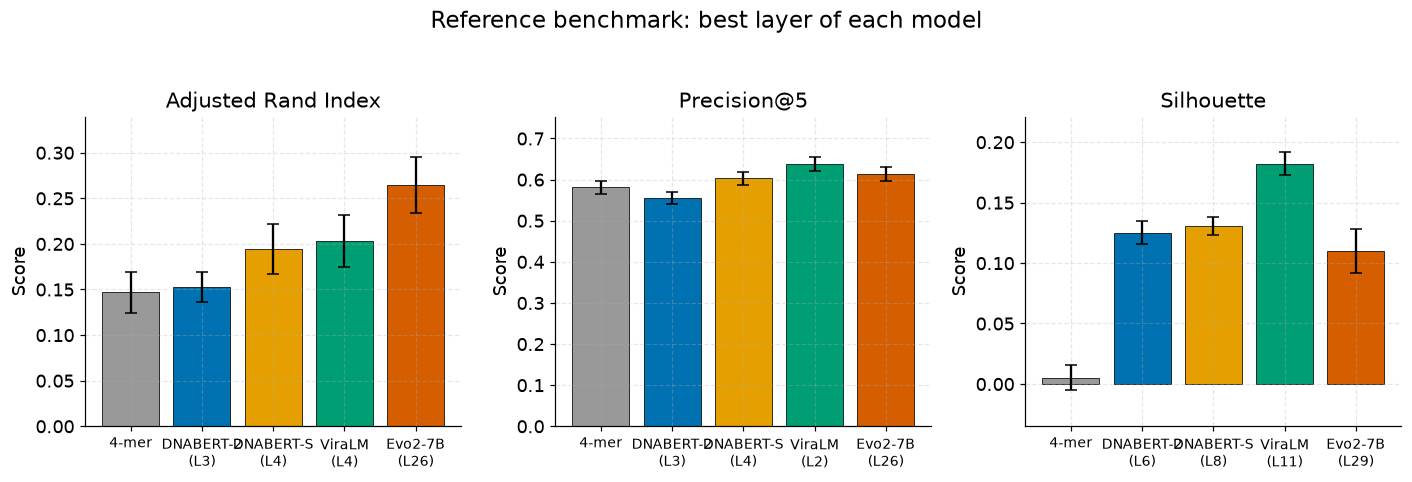

In [9]:
df = load_table("fig1_reference_benchmark")
panels = [("ARI", "Adjusted Rand Index"), ("P5", "Precision@5"), ("silh", "Silhouette")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (metric, title) in zip(axes, panels):
    d = df[df["metric"] == metric].set_index("model").reindex(MODELS)
    ax.bar(range(len(MODELS)), d["mean"], yerr=d["std"], capsize=4,
           color=[MODEL_COLOR[m] for m in MODELS], edgecolor="black", linewidth=0.5)
    labels = [DISPLAY[m] if m == "kmer" else f"{DISPLAY[m]}\n(L{int(d.loc[m, 'best_layer'])})" for m in MODELS]
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(title); ax.set_ylabel("Score"); ax.margins(y=0.15)
fig.suptitle("Reference benchmark: best layer of each model", fontsize=15, y=1.04)
fig.tight_layout()
save_figure(fig, "fig1_reference_benchmark", kind="main")

### Fig. 2

  figure   ->  results/figures/main/fig2_layerwise.{png,pdf}


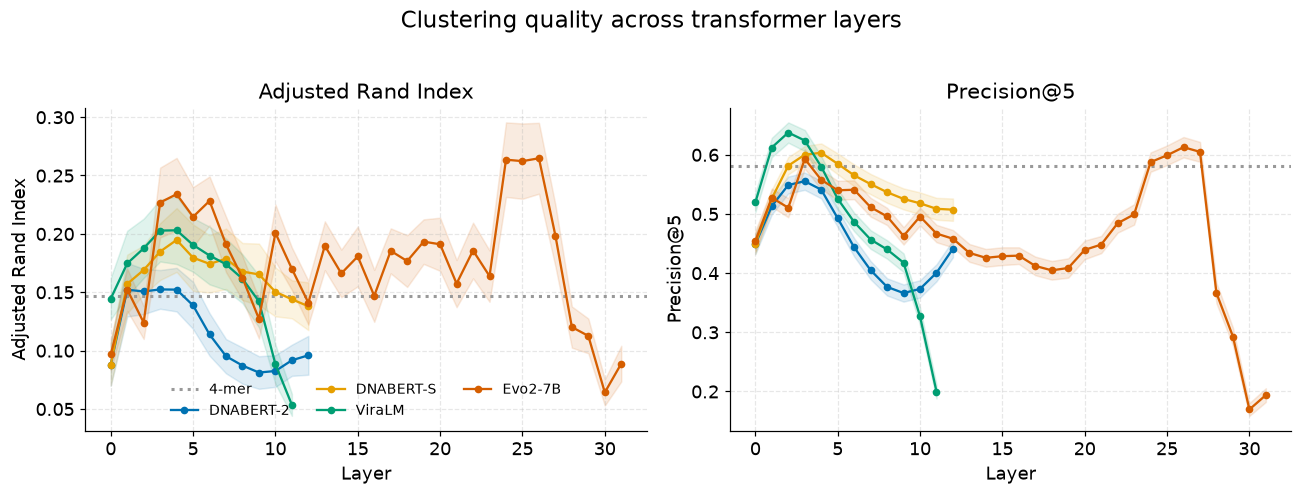

In [10]:
df = load_table("fig2_layerwise")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (metric, title) in zip(axes, [("ARI", "Adjusted Rand Index"), ("P5", "Precision@5")]):
    for model in MODELS:
        d = df[(df["metric"] == metric) & (df["model"] == model)].sort_values("layer")
        if model == "kmer":                                  # single-layer baseline -> dashed line
            ax.axhline(d["mean"].iloc[0], ls=":", lw=2, color=MODEL_COLOR[model], label=DISPLAY[model])
        else:
            ax.plot(d["layer"], d["mean"], "-o", ms=4, color=MODEL_COLOR[model], label=DISPLAY[model])
            ax.fill_between(d["layer"], d["mean"] - d["std"], d["mean"] + d["std"],
                            color=MODEL_COLOR[model], alpha=0.12)
    ax.set_xlabel("Layer"); ax.set_ylabel(title); ax.set_title(title)
axes[0].legend(loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Clustering quality across transformer layers", fontsize=15, y=1.02)
fig.tight_layout()
save_figure(fig, "fig2_layerwise", kind="main")

### Fig. 3

  figure   ->  results/figures/main/fig3_kmer_sweep.{png,pdf}


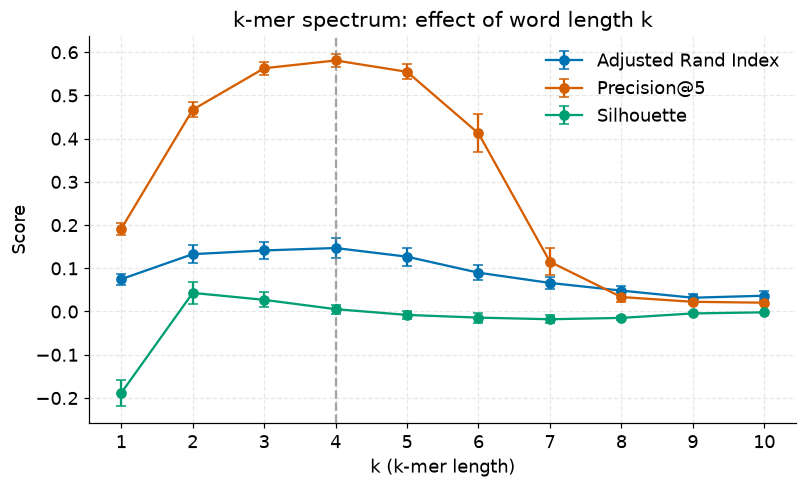

In [11]:
df = load_table("fig3_kmer_sweep").sort_values("k")
series = [("ARI_mean", "ARI_std", "Adjusted Rand Index", "#0072B2"),
          ("P@5_mean", "P@5_std", "Precision@5", "#D55E00"),
          ("Silhouette_mean", "Silhouette_std", "Silhouette", "#009E73")]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for mcol, scol, label, color in series:
    ax.errorbar(df["k"], df[mcol], yerr=df[scol], marker="o", capsize=3, color=color, label=label)
ax.axvline(4, ls="--", color="gray", alpha=0.7)
ax.set_xlabel("k (k-mer length)"); ax.set_ylabel("Score")
ax.set_title("k-mer spectrum: effect of word length k")
ax.set_xticks(df["k"]); ax.legend()
fig.tight_layout()
save_figure(fig, "fig3_kmer_sweep", kind="main")

### Fig. 4

  figure   ->  results/figures/main/fig4_newvirus_p5.{png,pdf}


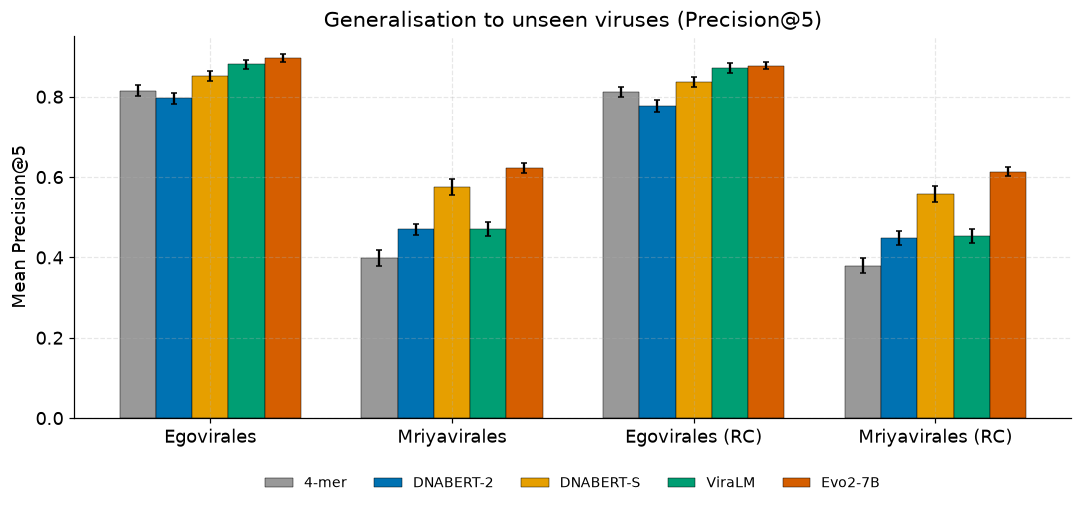

In [12]:
df = load_table("fig4_newvirus_p5")
order = ["Egovirales", "Mriyavirales", "Egovirales (RC)", "Mriyavirales (RC)"]
fig, ax = plt.subplots(figsize=(10, 4.8))
w, x = 0.15, np.arange(len(order))
for i, model in enumerate(MODELS):
    d = df[df["model"] == model].set_index("group").reindex(order)
    ax.bar(x + (i - (len(MODELS) - 1) / 2) * w, d["mean"], w, yerr=d["std"], capsize=2,
           color=MODEL_COLOR[model], label=DISPLAY[model], edgecolor="black", linewidth=0.3)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("Mean Precision@5"); ax.set_title("Generalisation to unseen viruses (Precision@5)")
ax.legend(ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
save_figure(fig, "fig4_newvirus_p5", kind="main")

### Fig. 5

  figure   ->  results/figures/main/fig5_cross_p5.{png,pdf}


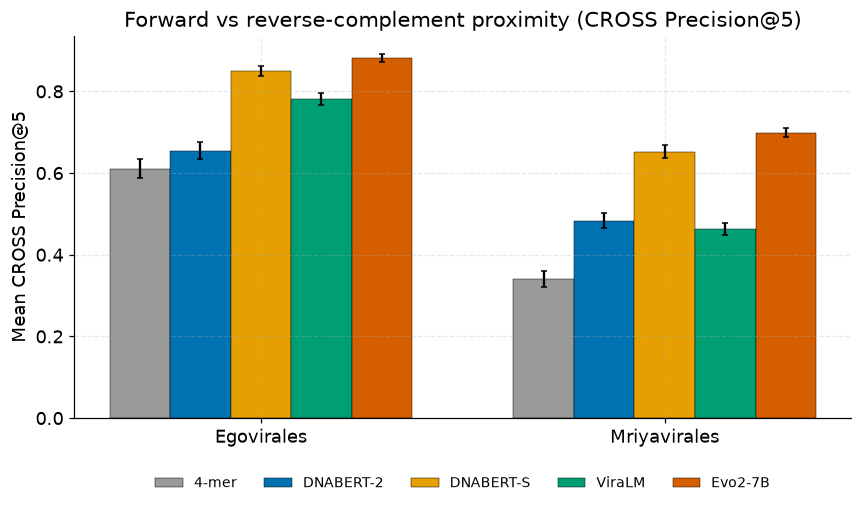

In [13]:
df = load_table("fig5_cross_p5")
order = ["Egovirales", "Mriyavirales"]
fig, ax = plt.subplots(figsize=(8, 4.8))
w, x = 0.15, np.arange(len(order))
for i, model in enumerate(MODELS):
    d = df[df["model"] == model].set_index("group").reindex(order)
    ax.bar(x + (i - (len(MODELS) - 1) / 2) * w, d["mean"], w, yerr=d["std"], capsize=2,
           color=MODEL_COLOR[model], label=DISPLAY[model], edgecolor="black", linewidth=0.3)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("Mean CROSS Precision@5")
ax.set_title("Forward vs reverse-complement proximity (CROSS Precision@5)")
ax.legend(ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
save_figure(fig, "fig5_cross_p5", kind="main")

### Fig. 6

  figure   ->  results/figures/main/fig6_pk_vs_k.{png,pdf}


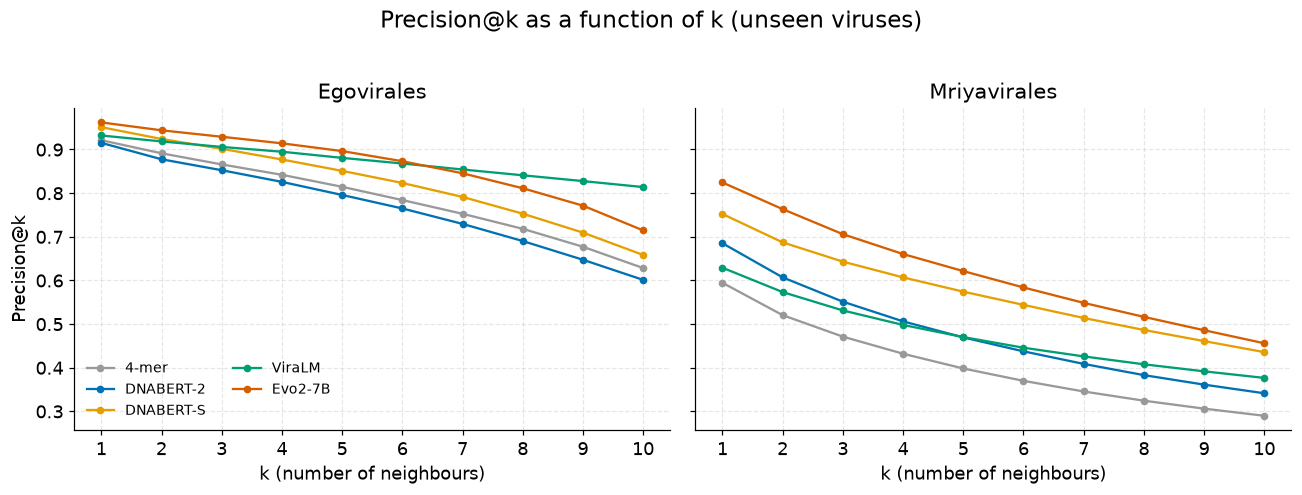

In [14]:
df = load_table("fig6_pk_vs_k")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, virus in zip(axes, ["Egovirales", "Mriyavirales"]):
    for model in MODELS:
        d = df[(df["virus"] == virus) & (df["model"] == model)].sort_values("k")
        ax.plot(d["k"], d["mean"], "-o", ms=4, color=MODEL_COLOR[model], label=DISPLAY[model])
    ax.set_xlabel("k (number of neighbours)"); ax.set_title(virus); ax.set_xticks(range(1, 11))
axes[0].set_ylabel("Precision@k"); axes[0].legend(fontsize=9, ncol=2)
fig.suptitle("Precision@k as a function of k (unseen viruses)", fontsize=15, y=1.02)
fig.tight_layout()
save_figure(fig, "fig6_pk_vs_k", kind="main")

### Fig. 7

  figure   ->  results/figures/main/fig7_pk_vs_cross.{png,pdf}


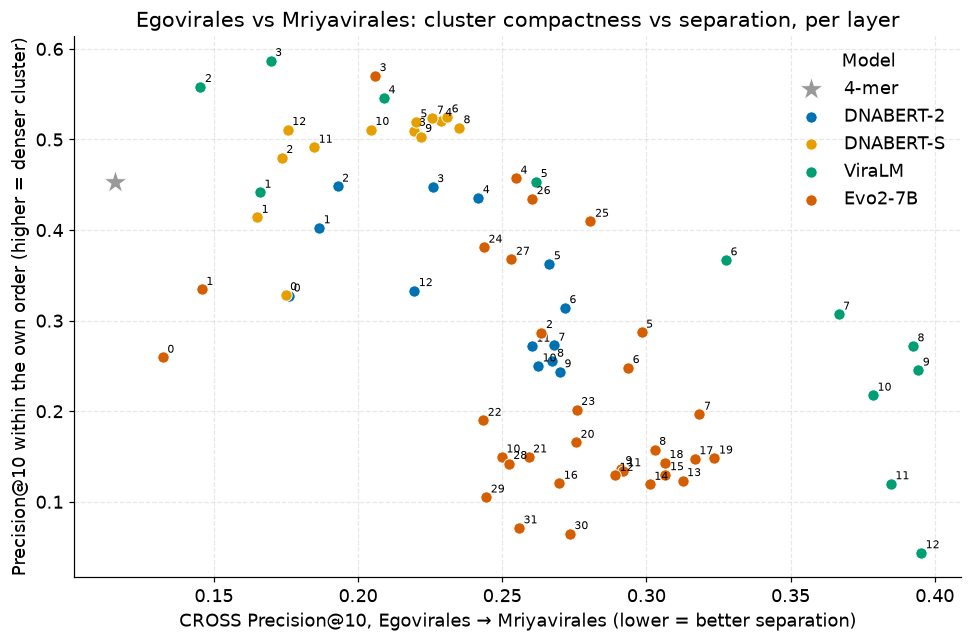

In [15]:
df = load_table("fig7_pk_vs_cross")
fig, ax = plt.subplots(figsize=(9, 6))
for model in MODELS:
    d = df[df["model"] == model]
    if d.empty:
        continue
    baseline = model == "kmer"                   # layer-less -> one star instead of a cloud
    ax.scatter(d["cross_p_at_10"], d["p_at_10"],
               marker="*" if baseline else "o", s=260 if baseline else 55,
               color=MODEL_COLOR[model], label=DISPLAY[model],
               edgecolor="white", linewidth=0.6, zorder=3)
    for _, r in d.iterrows():
        layer = "".join(ch for ch in str(r["layer"]) if ch.isdigit())
        if layer:
            ax.annotate(layer, (r["cross_p_at_10"], r["p_at_10"]),
                        fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("CROSS Precision@10, Egovirales → Mriyavirales (lower = better separation)")
ax.set_ylabel("Precision@10 within the own order (higher = denser cluster)")
ax.set_title("Egovirales vs Mriyavirales: cluster compactness vs separation, per layer")
ax.legend(title="Model")
fig.tight_layout()
save_figure(fig, "fig7_pk_vs_cross", kind="main")


---
All main-text figures written to `results/figures/main/` (PNG + PDF); their numbers
live in `results/figure_data/`. See `results/README.md` for the full figure map.